In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import matplotlib.ticker as mticker
import math
import itertools
from typing import Literal
from matplotlib.ticker import FuncFormatter
from matplotlib.axes import Axes
from matplotlib.figure import Figure
import seaborn.objects as so
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

In [2]:
from sklearn import set_config
set_config(transform_output='pandas', display='diagram')

# Notebook Purpose

Trong notebook này, ta sẽ dùng LightGBM không có Class Weighting và có Class Weighting để thực hiện các phương pháp cải thiện Calibration, để từ đó chọn ra mô hình tốt nhất sau khi cải thiện

In [3]:
application_train = pd.read_csv('/Users/thuyduc/Projects/AI/AI Sandbox/Services/CreditRiskAgent/data/raw/application_train_sample.csv')
bureau = pd.read_csv('/Users/thuyduc/Projects/AI/AI Sandbox/Services/CreditRiskAgent/data/raw/bureau_sample.csv')
bureau_balance = pd.read_csv('/Users/thuyduc/Projects/AI/AI Sandbox/Services/CreditRiskAgent/data/raw/bureau_balance_sample.csv')
credit_card_balance = pd.read_csv('/Users/thuyduc/Projects/AI/AI Sandbox/Services/CreditRiskAgent/data/raw/credit_card_balance_sample.csv')
installments_payments = pd.read_csv('/Users/thuyduc/Projects/AI/AI Sandbox/Services/CreditRiskAgent/data/raw/instalments_payments_sample.csv')
previous_application = pd.read_csv('/Users/thuyduc/Projects/AI/AI Sandbox/Services/CreditRiskAgent/data/raw/previous_application_sample.csv')
POS_CASH_balance = pd.read_csv('/Users/thuyduc/Projects/AI/AI Sandbox/Services/CreditRiskAgent/data/raw/POS_CASH_balance_sample.csv')

In [4]:
from sklearn.model_selection import train_test_split

X = application_train.drop(columns=['TARGET'])
y = application_train['TARGET']

# chia tập dữ liệu cho application_train
X_train, X_val, y_train, y_val = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X_train, y_train, stratify=y_train, test_size=0.2, random_state=42)

application_train_train = pd.concat([X_train, y_train], axis=1)
application_train_val = pd.concat([X_val, y_val], axis=1)
application_train_test = pd.concat([X_test, y_test], axis=1)

SK_ID_CURR_train = X_train['SK_ID_CURR'].values
SK_ID_CURR_val = X_val['SK_ID_CURR'].values
SK_ID_CURR_test = X_test['SK_ID_CURR'].values

# chia tập dữ liệu cho bureau
bureau_train = bureau[bureau['SK_ID_CURR'].isin(SK_ID_CURR_train)]
bureau_val = bureau[bureau['SK_ID_CURR'].isin(SK_ID_CURR_val)]
bureau_test = bureau[bureau['SK_ID_CURR'].isin(SK_ID_CURR_test)]

SK_ID_BUREAU_train = bureau_train['SK_ID_BUREAU'].values
SK_ID_BUREAU_val = bureau_val['SK_ID_BUREAU'].values
SK_ID_BUREAU_test = bureau_test['SK_ID_BUREAU'].values

# chia tập dữ liệu cho previous_application
previous_application_train = previous_application[previous_application['SK_ID_CURR'].isin(SK_ID_CURR_train)]
previous_application_val = previous_application[previous_application['SK_ID_CURR'].isin(SK_ID_CURR_val)]
previous_application_test = previous_application[previous_application['SK_ID_CURR'].isin(SK_ID_CURR_test)]

SK_ID_PREV_train = previous_application_train['SK_ID_PREV'].values
SK_ID_PREV_val = previous_application_val['SK_ID_PREV'].values
SK_ID_PREV_test = previous_application_test['SK_ID_PREV'].values

# chia tập dữ liệu cho bureau_balance
bureau_balance_train = bureau_balance[bureau_balance['SK_ID_BUREAU'].isin(SK_ID_BUREAU_train)]
bureau_balance_val = bureau_balance[bureau_balance['SK_ID_BUREAU'].isin(SK_ID_BUREAU_val)]
bureau_balance_test = bureau_balance[bureau_balance['SK_ID_BUREAU'].isin(SK_ID_BUREAU_test)]

# chia tập dữ liệu cho POS_CASH_balance
filter_pos_cash_train = (POS_CASH_balance['SK_ID_CURR'].isin(SK_ID_CURR_train)) & (POS_CASH_balance['SK_ID_PREV'].isin(SK_ID_PREV_train))
filter_pos_cash_val = (POS_CASH_balance['SK_ID_CURR'].isin(SK_ID_CURR_val)) & (POS_CASH_balance['SK_ID_PREV'].isin(SK_ID_PREV_val))
filter_pos_cash_test = (POS_CASH_balance['SK_ID_CURR'].isin(SK_ID_CURR_test)) & (POS_CASH_balance['SK_ID_PREV'].isin(SK_ID_PREV_test))

POS_CASH_balance_train = POS_CASH_balance[filter_pos_cash_train]
POS_CASH_balance_val = POS_CASH_balance[filter_pos_cash_val]
POS_CASH_balance_test = POS_CASH_balance[filter_pos_cash_test]

# chia tập dữ liệu cho instalments_payments
filter_instalments_train = (installments_payments['SK_ID_CURR'].isin(SK_ID_CURR_train)) & (installments_payments['SK_ID_PREV'].isin(SK_ID_PREV_train))
filter_instalments_val = (installments_payments['SK_ID_CURR'].isin(SK_ID_CURR_val)) & (installments_payments['SK_ID_PREV'].isin(SK_ID_PREV_val))
filter_instalments_test = (installments_payments['SK_ID_CURR'].isin(SK_ID_CURR_test)) & (installments_payments['SK_ID_PREV'].isin(SK_ID_PREV_test))

installments_payments_train = installments_payments[filter_instalments_train]
installments_payments_val = installments_payments[filter_instalments_val]
installments_payments_test = installments_payments[filter_instalments_test]

# chia tập dữ liệu cho credit_card_balance
filter_credit_train = (credit_card_balance['SK_ID_CURR'].isin(SK_ID_CURR_train)) & (credit_card_balance['SK_ID_PREV'].isin(SK_ID_PREV_train))
filter_credit_val = (credit_card_balance['SK_ID_CURR'].isin(SK_ID_CURR_val)) & (credit_card_balance['SK_ID_PREV'].isin(SK_ID_PREV_val))
filter_credit_test = (credit_card_balance['SK_ID_CURR'].isin(SK_ID_CURR_test)) & (credit_card_balance['SK_ID_PREV'].isin(SK_ID_PREV_test))

credit_card_balance_train = credit_card_balance[filter_credit_train]
credit_card_balance_val = credit_card_balance[filter_credit_val]
credit_card_balance_test = credit_card_balance[filter_credit_test]

# Định nghĩa Custom Transformer và Pipeline

In [5]:
from matplotlib.ticker import FuncFormatter
from matplotlib.axes import Axes
from matplotlib.figure import Figure
import matplotlib.ticker as mticker
import math
import itertools
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

class BarPlot:
    def __init__(self, df:pd.DataFrame):
        self.df = df

    @staticmethod
    def readable_numbers(x: float) -> str:
        """
        takes a large number and formats it into K,M to make it more readable

        Args
            x: float value to format

        Returns
            str: formatted string
        """
        if x >= 1e6:
            s = '{:1.2f}M'.format(x*1e-6)
        else:
            s = '{:1.2f}K'.format(x*1e-3)
        return s
    
    def set_locator(self, axes: Axes):
        """
        Format x, y ticklabels into more readable form

        Args
            axes: matplotlib axes to format x, y ticklabels
        """
        def is_number(x):
            x = x.replace('−', '-')
            try:
                float(x)
                return True
            except ValueError:
                return False
    
        x_ticklabels = [tick.get_text() for tick in axes.get_xticklabels()]
        y_ticklabels = [tick.get_text() for tick in axes.get_yticklabels()]
    
        formatter = FuncFormatter(lambda val, pos: self.readable_numbers(val))

        if is_number(x_ticklabels[0]) == True:
            axes.xaxis.set_major_formatter(formatter)
        if is_number(y_ticklabels[0]) == True:
            axes.yaxis.set_major_formatter(formatter)

    def single_plot(
        self,
        x_axis: str,
        y_axis: str,
        hue: str | None,
        kwarg: dict|None = None,
        readable_label: bool = False,
        ax: Axes = None
    ) -> Axes:
        """
        Draw a beautiful and readable bar plot.
    
        Args:
            x_axis: column for x-axis
            y_axis: column for y-axis
            hue: column to group bars (optional)
            readable_label: whether to display readable number labels
            ax: matplotlib axes to draw plot
            kwarg: other keyword arguments (e.g., from seaborn barplot)
        """
    
        # --- Setup Axes ---
        if ax is None:
            ax = plt.gca()
    
        # --- 🌟 Modern aesthetic theme ---
        palette = sns.color_palette("Spectral", n_colors=self.df[hue].nunique()) if hue else "viridis"
        # or: "rocket", "magma", "coolwarm", "crest", "flare", "viridis"

        if kwarg is None:
            kwarg = {}
        # --- Draw the barplot ---
        bar = sns.barplot(
            data=self.df,
            x=x_axis,
            y=y_axis,
            hue=hue,
            ax=ax,
            # palette=palette,
            edgecolor="black",
            linewidth=1.2,
            **kwarg
        )
    
        # --- 🧠 Title & Labels ---
        ax.set_title(
            f'{y_axis} by {x_axis}',
            fontdict={
                'fontsize': 16,
                'fontweight': 'regular',
                # 'fontname': 'Times New Roman'
            },
            pad=15
        )
        ax.set_xlabel(x_axis, fontsize=12, labelpad=10)
        ax.set_ylabel(y_axis, fontsize=12, labelpad=10)
    
        # --- ✨ Ticks & Grid ---
        ax.tick_params(axis='x', labelsize=10, rotation=0)
        ax.tick_params(axis='y', labelsize=10)
        ax.grid(True, axis='y', linestyle='--', alpha=0.3)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_color('gray')
        ax.spines['bottom'].set_color('gray')
    
        # --- 🎨 Legend ---
        if hue is not None:
            ax.legend(
                title=hue,
                title_fontsize=11,
                fontsize=10,
                loc='best',
                frameon=False
            )
    
        # --- 💬 Bar labels ---
        if readable_label:
            for container in bar.containers:
                labels = [p.get_height() for p in container]
                bar.bar_label(
                    container,
                    labels=labels,
                    label_type='edge',
                    fontsize=9,
                    # fontname='Times New Roman',
                    color='black',
                    padding=2
                )
            self.set_locator(bar)
    
        # # --- 🌤️ Tighten layout ---
        # plt.tight_layout()
    
        return bar

    def multiple_plots(self, x_axis_list: list[str], y_axis_list: list[str], hue_list: list[str|None], kwarg: dict,
                       plots_each_row: int, readable_label: bool = False) -> (Figure, np.array([Axes])):
        """
        Draw multiple plots

        Args
            Same as single_plot
            y_axis_list: list of columns for y axis
            plots_each_row: number of plots for each row in matplotlib figure
            kwarg: other keyword arguments if needed.
        """
        
        combination = list(zip(x_axis_list, y_axis_list, hue_list))
        
        length = len(combination)
        number_rows = math.ceil(length / plots_each_row)
    
        fig, axes = plt.subplots(nrows=number_rows, ncols=plots_each_row, figsize=(16, 8),
                                sharey=False)
        
        axes = np.array(axes).reshape(number_rows, plots_each_row)
    
        coordinates = list(itertools.product(range(number_rows), range(plots_each_row)))
    
        for coor, com in zip(coordinates, combination):
            x, y, hue = com
            ax = axes[coor]
            self.single_plot(
                x_axis=x,
                y_axis=y,
                hue=hue,
                readable_label=readable_label,
                kwarg=kwarg,
                ax=ax
            )
    
        # hide any unused axes
        for coor in coordinates[length:]:
            fig.delaxes(axes[coor])

        return fig, axes

In [6]:
class AddPrefix(BaseEstimator, TransformerMixin):
    def __init__(self, prefix:str, exclude:list[str]):
        """
        Used to add prefix to columns' name
        
        Args:
            prefix: prefix added to columns' name
            exclude: columns that don't need prefix
        """
        self.prefix = prefix
        self.exclude = exclude

    def fit(self, X:pd.DataFrame, y=None):
        X_copy = X.copy()
        self.new_cols_name_ = [
            col if col in self.exclude else f'{self.prefix}_{col}'
            for col in X_copy.columns
        ]
        return self

    def transform(self, X:pd.DataFrame):
        X_copy = X.copy()
        X_copy.columns = self.new_cols_name_
        return X_copy

    def get_feature_names_out(self, input_features=None): # must have this method
        # must have 'input_features' parameter
        return self.new_cols_name_

In [7]:
class RemoveFeature(BaseEstimator, TransformerMixin):
    def __init__(self, columns_removed:list[str]):
        """
        columns_removed: columns which will be removed from dataset
        """
        self.columns_removed = columns_removed

    def fit(self, X:pd.DataFrame, y=None):
        missing = set(self.columns_removed) - set(X.columns) # check if columns's name removed is misspelled
        if missing:
            raise ValueError(f"Các cột sau không tồn tại trong dữ liệu: {missing}")
        
        # Giữ nguyên thứ tự cột gốc, chỉ loại bỏ cột cần xóa
        self.columns_selected_ = [
            col for col in X.columns if col not in self.columns_removed
        ]
        return self

    def transform(self, X:pd.DataFrame):
        X_copy = X.copy()
        X_new = X_copy[self.columns_selected_]
        return X_new

    def get_feature_names_out(self, input_features=None): # must have this method
        # must have 'input_features' parameter
        return self.columns_selected_

In [8]:
class Aggeration(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols:list[str], num_cols:list[str], groupby_col:str):
        """
        Used to perform aggregation by specific columns, num_cols and cat_cols will have differenct aggregation
        
        Args:
            cat_cols: categorical column's name
            num_cols: numerical column's name
            groupby_col: specific column's name used for groupby to perform aggregation
        """
        if groupby_col in num_cols:
            num_cols.remove(groupby_col)

        self.cat_cols = cat_cols
        self.num_cols = num_cols
        self.groupby_col = groupby_col

    def _build_agg_dict(self):
        agg_dict = {}
        for col in self.cat_cols:
            agg_dict[col] = ['mean'] # ['sum', 'mean']
        for col in self.num_cols:
            agg_dict[col] = ['mean', 'max'] # ['min', 'max', 'mean']
        return agg_dict
    
    def fit(self, X:pd.DataFrame, y=None):
        agg_dict = self._build_agg_dict()
        self.new_cols_name_ = [self.groupby_col] + [
            f'{col}_{stat.lower()}' for col, stats in agg_dict.items() for stat in stats
        ]
        return self

    def transform(self, X:pd.DataFrame):
        X_copy = X.copy()
        agg_dict = self._build_agg_dict()

        X_agg = X_copy.groupby(self.groupby_col).agg(agg_dict)
        X_agg.columns = self.new_cols_name_[1:]
        X_agg.reset_index(inplace=True)
        
        return X_agg

    def get_feature_names_out(self, input_features=None): # must have this method
        # must have 'input_features' parameter
        return self.new_cols_name_

In [9]:
class FrequencyGrouping(BaseEstimator, TransformerMixin):
    def __init__(self, threshold = 0.999999):
        self.threshold = threshold
    
    def fit(self, X: pd.DataFrame, y=None):
        X_copy = X.copy()
        self.dict_categories_ = {}
        columns = X_copy.columns

        for col in columns:
            col: str
            frequency = X_copy[col].value_counts(normalize=True)
            cum_frequency = np.cumsum(frequency)

            kept_categories = frequency[cum_frequency <= self.threshold].index.tolist()
            self.dict_categories_[col] = kept_categories

        return self
    
    def transform(self, X: pd.DataFrame):
        X_copy = X.copy()
        
        for col, kept_categories in self.dict_categories_.items():
            col: str
            kept_categories: list
            X_copy[col] = X_copy[col].apply(lambda x: x if x in kept_categories else 'Others')

        return X_copy

In [10]:
from sklearn.preprocessing import OrdinalEncoder
class ApplicationTrainPipeline(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X:pd.DataFrame, y=None):
        X_copy = X.copy()

        # auto detect features with missing ratio > 0.1, to remove them
        missing_ratio = X_copy.isnull().mean().astype(float).to_frame()
        missing_ratio = missing_ratio.rename(columns={0: "missing_ratio"})
        columns_remove_application_train = list(missing_ratio[missing_ratio['missing_ratio'] > 0.5].index)
        
        self.missing_ratio_feature_removed_application_train_ = RemoveFeature(columns_removed = columns_remove_application_train)
        X_copy = self.missing_ratio_feature_removed_application_train_.fit_transform(X_copy)

        # encode for categorical features
        obj_columns = list(X_copy.select_dtypes('object').columns)
        self.categorical_encoder_ = ColumnTransformer(
            transformers=[
                ('ordinal_encoding', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=np.nan), obj_columns)
            ],
            remainder='passthrough',
            verbose_feature_names_out=False, # not containing the transformer name in columns of Dataframe
            # force_int_remainder_cols=False
        )
        X_copy = self.categorical_encoder_.fit_transform(X_copy)

        # auto detect binary features having ratio < 0.1 or ratio > 1 - 0.1, to remove them
        all_cols = list(X_copy.columns)
        binary_columns = [col for col in all_cols if set(X_copy[col].dropna().unique()).issubset({0, 1})]
        binary_columns_mean = X_copy[binary_columns].mean()
        binary_columns_remove = list(
            binary_columns_mean[(binary_columns_mean < 0.02) |
                         (binary_columns_mean > 1 - 0.02)].index
        )
        # binary_columns_remove.remove('TARGET')

        self.binary_feature_removed_application_train_ = RemoveFeature(columns_removed = binary_columns_remove)
        X_copy = self.binary_feature_removed_application_train_.fit_transform(X_copy)

        self.application_train_add_prefix_ = AddPrefix(prefix='AT', exclude=['SK_ID_CURR'])
        X_copy = self.application_train_add_prefix_.fit_transform(X_copy)
        
        return self

    def transform(self, X:pd.DataFrame):
        X_copy = X.copy()
        X_final = self.missing_ratio_feature_removed_application_train_.transform(X_copy)
        X_final = self.categorical_encoder_.transform(X_final)
        X_final = self.binary_feature_removed_application_train_.transform(X_final)
        X_final = self.application_train_add_prefix_.transform(X_final)
        return X_final

    def get_feature_names_out(self, input_features=None):
        return self.application_train_add_prefix_.get_feature_names_out()

In [11]:
class BureauBalancePipeline(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X:pd.DataFrame, y=None):
        X_copy = X.copy()
        cat_cols = list(X_copy.select_dtypes(include=['object']).columns)
        num_cols = list(X_copy.select_dtypes(include=['number']).columns)

        cat_pipeline = Pipeline([
            ('frequency_grouping', FrequencyGrouping()),
            ('one_hot_encode', OneHotEncoder(sparse_output=False, drop='if_binary', handle_unknown='ignore')),
        ])
        
        self.cat_cols_transformer_ = ColumnTransformer(
            transformers=[
                ('cat_processing', cat_pipeline, cat_cols)
            ],
            remainder='passthrough',
            verbose_feature_names_out=False, # not containing the transformer name in columns of Dataframe
            # force_int_remainder_cols=False
        )
        X_copy = self.cat_cols_transformer_.fit_transform(X_copy)

        cat_cols_after_onehot = [col for col in X_copy.columns if col.startswith(tuple([f"{column}_" for column in cat_cols]))]
        self.aggregate_ = Aggeration(cat_cols=cat_cols_after_onehot, num_cols=num_cols, groupby_col='SK_ID_BUREAU')
        X_copy = self.aggregate_.fit_transform(X_copy)

        self.bureau_balance_add_prefix_ = AddPrefix(prefix='BB', exclude=['SK_ID_BUREAU'])
        X_copy = self.bureau_balance_add_prefix_.fit_transform(X_copy)
        
        return self

    def transform(self, X:pd.DataFrame):
        X_copy = X.copy()
        X_final = self.cat_cols_transformer_.transform(X_copy)
        X_final = self.aggregate_.transform(X_final)
        X_final = self.bureau_balance_add_prefix_.transform(X_final)
        
        return X_final

    def get_feature_names_out(self, input_features=None):
        return self.bureau_balance_add_prefix_.get_feature_names_out()

In [12]:
class POSCASHPipeline(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X:pd.DataFrame, y=None):
        X_copy = X.copy()
        X_copy.drop(columns=['SK_ID_CURR'], inplace=True)
        cat_cols = list(X_copy.select_dtypes(include=['object']).columns)
        num_cols = list(X_copy.select_dtypes(include=['number']).columns)
        
        cat_pipeline = Pipeline([
            ('frequency_grouping', FrequencyGrouping()),
            ('one_hot_encode', OneHotEncoder(sparse_output=False, drop='if_binary', handle_unknown='ignore')),
        ])
        
        self.cat_cols_transformer_ = ColumnTransformer(
            transformers=[
                ('cat_processing', cat_pipeline, cat_cols)
            ],
            remainder='passthrough',
            verbose_feature_names_out=False, # not containing the transformer name in columns of Dataframe
            # force_int_remainder_cols=False
        )
        X_copy = self.cat_cols_transformer_.fit_transform(X_copy)

        cat_cols_after_onehot = [col for col in X_copy.columns if col.startswith(tuple([f"{column}_" for column in cat_cols]))]
        self.aggregate_ = Aggeration(cat_cols=cat_cols_after_onehot, num_cols=num_cols, groupby_col='SK_ID_PREV')
        X_copy = self.aggregate_.fit_transform(X_copy)
        
        self.pos_cash_add_prefix_ = AddPrefix(prefix='PC', exclude=['SK_ID_PREV'])
        X_copy = self.pos_cash_add_prefix_.fit_transform(X_copy)
        
        return self

    def transform(self, X:pd.DataFrame):
        X_copy = X.copy()
        X_copy.drop(columns=['SK_ID_CURR'], inplace=True)
        
        X_final = self.cat_cols_transformer_.transform(X_copy)
        X_final = self.aggregate_.transform(X_final)
        X_final = self.pos_cash_add_prefix_.transform(X_final)
        
        return X_final

    def get_feature_names_out(self, input_features=None):
        return self.pos_cash_add_prefix_.get_feature_names_out()

In [13]:
class InstallmentPaymentPipeline(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X:pd.DataFrame, y=None):
        X_copy = X.copy()
        X_copy.drop(columns=['SK_ID_CURR'], inplace=True)
        cat_cols = list(X_copy.select_dtypes(include=['object']).columns) # empty list
        num_cols = list(X_copy.select_dtypes(include=['number']).columns)
        
        self.aggregate_ = Aggeration(cat_cols=cat_cols, num_cols=num_cols, groupby_col='SK_ID_PREV')
        X_copy = self.aggregate_.fit_transform(X_copy)

        self.installment_payment_add_prefix_ = AddPrefix(prefix='IP', exclude=['SK_ID_PREV'])
        X_copy = self.installment_payment_add_prefix_.fit_transform(X_copy)

        return self

    def transform(self, X:pd.DataFrame):
        X_copy = X.copy()
        X_copy.drop(columns=['SK_ID_CURR'], inplace=True)
        
        X_final = self.aggregate_.transform(X_copy)
        X_final = self.installment_payment_add_prefix_.transform(X_final)
        
        return X_final

    def get_feature_names_out(self, input_features=None):
        return self.installment_payment_add_prefix_.get_feature_names_out()

In [14]:
class CreditCardPipeline(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X:pd.DataFrame, y=None):
        X_copy = X.copy()
        X_copy.drop(columns=['SK_ID_CURR'], inplace=True)

        # auto detect features with missing ratio > 0.1, to remove them
        missing_ratio = X_copy.isnull().mean().astype(float).to_frame()
        missing_ratio = missing_ratio.rename(columns={0: "missing_ratio"})
        columns_remove_credit_card = list(missing_ratio[missing_ratio['missing_ratio'] > 0.5].index)

        self.feature_removed_credit_card_ = RemoveFeature(columns_removed = columns_remove_credit_card)
        X_copy = self.feature_removed_credit_card_.fit_transform(X_copy)

        cat_cols = list(X_copy.select_dtypes(include=['object']).columns)
        num_cols = list(X_copy.select_dtypes(include=['number']).columns)

        cat_pipeline = Pipeline([
            ('frequency_grouping', FrequencyGrouping()),
            ('one_hot_encode', OneHotEncoder(sparse_output=False, drop='if_binary', handle_unknown='ignore')),
        ])
        
        self.cat_cols_transformer_ = ColumnTransformer(
            transformers=[
                ('cat_processing', cat_pipeline, cat_cols)
            ],
            remainder='passthrough',
            verbose_feature_names_out=False, # not containing the transformer name in columns of Dataframe
            # force_int_remainder_cols=False
        )
        X_copy = self.cat_cols_transformer_.fit_transform(X_copy)

        cat_cols_after_onehot = [col for col in X_copy.columns if col.startswith(tuple([f"{column}_" for column in cat_cols]))]
        self.aggregate_ = Aggeration(cat_cols=cat_cols_after_onehot, num_cols=num_cols, groupby_col='SK_ID_PREV')
        X_copy = self.aggregate_.fit_transform(X_copy)

        self.credit_card_add_prefix_ = AddPrefix(prefix='CC', exclude=['SK_ID_PREV'])
        X_copy = self.credit_card_add_prefix_.fit_transform(X_copy)
        
        return self

    def transform(self, X:pd.DataFrame):
        X_copy = X.copy()
        X_copy.drop(columns=['SK_ID_CURR'], inplace=True)
        
        X_final = self.feature_removed_credit_card_.transform(X_copy)
        X_final = self.cat_cols_transformer_.transform(X_final)
        X_final = self.aggregate_.transform(X_final)
        X_final = self.credit_card_add_prefix_.transform(X_final)
        
        return X_final

    def get_feature_names_out(self, input_features=None):
        return self.credit_card_add_prefix_.get_feature_names_out()

In [15]:
class BureauPipeline(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X:pd.DataFrame, y=None):
        X_copy = X.copy()

        # auto detect features with missing ratio > 0.1, to remove them
        missing_ratio = X_copy.isnull().mean().astype(float).to_frame()
        missing_ratio = missing_ratio.rename(columns={0: "missing_ratio"})
        columns_remove_bureau = list(missing_ratio[missing_ratio['missing_ratio'] > 0.5].index)

        self.feature_removed_bureau_ = RemoveFeature(columns_removed = columns_remove_bureau)
        X_copy = self.feature_removed_bureau_.fit_transform(X_copy)

        self.bureau_add_prefix_ = AddPrefix(prefix='B', exclude=['SK_ID_CURR', 'SK_ID_BUREAU'])
        X_copy = self.bureau_add_prefix_.fit_transform(X_copy)
        
        return self

    def transform(self, X:pd.DataFrame):
        X_copy = X.copy()
        
        X_final = self.feature_removed_bureau_.transform(X_copy)
        X_final = self.bureau_add_prefix_.transform(X_final)
        
        return X_final

    def get_feature_names_out(self, input_features=None):
        return self.bureau_add_prefix_.get_feature_names_out()

In [16]:
class PreviousApplicationPipeline(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X:pd.DataFrame, y=None):
        X_copy = X.copy()

        # auto detect features with missing ratio > 0.1, to remove them
        missing_ratio = X_copy.isnull().mean().astype(float).to_frame()
        missing_ratio = missing_ratio.rename(columns={0: "missing_ratio"})
        columns_remove_previous_application = list(missing_ratio[missing_ratio['missing_ratio'] > 0.5].index)
        
        self.feature_removed_previous_application_ = RemoveFeature(columns_removed = columns_remove_previous_application)
        X_copy = self.feature_removed_previous_application_.fit_transform(X_copy)

        self.previous_application_add_prefix_ = AddPrefix(prefix='PA', exclude=['SK_ID_CURR', 'SK_ID_PREV'])
        X_copy = self.previous_application_add_prefix_.fit_transform(X_copy)
        
        return self

    def transform(self, X:pd.DataFrame):
        X_copy = X.copy()
        
        X_final = self.feature_removed_previous_application_.transform(X_copy)
        X_final = self.previous_application_add_prefix_.transform(X_final)
        
        return X_final

    def get_feature_names_out(self, input_features=None):
        return self.previous_application_add_prefix_.get_feature_names_out()

In [17]:
class MergePipeline:
    def __init__(self):
        self.bureau_balance_pipeline = BureauBalancePipeline()
        self.installment_payment_pipeline = InstallmentPaymentPipeline()
        self.pos_cash_pipeline = POSCASHPipeline()
        self.credit_card_pipeline = CreditCardPipeline()
        self.previous_application_pipeline = PreviousApplicationPipeline()
        self.bureau_pipeline = BureauPipeline()
        self.application_pipeline = ApplicationTrainPipeline()

        # Lưu các transformer/aggregator theo tên nhóm, thay vì tạo nhiều thuộc tính rời rạc
        self.group_transformers_ = {}

    def _encode_and_aggregate_fit(self, df: pd.DataFrame, group_name: str, groupby_col: str = 'SK_ID_CURR'):
        """
        Dùng khi fit: one-hot encode + aggregate cho 1 nhóm bảng (bureau hoặc previous_application),
        đồng thời lưu lại các transformer đã fit để dùng lại lúc transform.
        """
        cat_cols = list(df.select_dtypes(include=['object']).columns)
        num_cols = list(df.select_dtypes(include=['number']).columns)

        cat_pipeline = Pipeline([
            ('frequency_grouping', FrequencyGrouping()),
            ('one_hot_encode', OneHotEncoder(sparse_output=False, drop='if_binary', handle_unknown='ignore')),
        ])
        
        cat_transformer = ColumnTransformer(
            transformers=[
                ('cat_processing', cat_pipeline, cat_cols)
            ],
            remainder='passthrough',
            verbose_feature_names_out=False,
        )
        df_encoded = cat_transformer.fit_transform(df)

        cat_cols_after_onehot = [
            col for col in df_encoded.columns
            if col.startswith(tuple(f"{c}_" for c in cat_cols))
        ]

        aggregator = Aggeration(cat_cols=cat_cols_after_onehot, num_cols=num_cols, groupby_col=groupby_col)
        df_agg = aggregator.fit_transform(df_encoded)

        # Lưu lại để transform() dùng sau này
        self.group_transformers_[group_name] = {
            'cat_transformer': cat_transformer,
            'aggregator': aggregator,
        }

        return df_agg

    def _encode_and_aggregate_transform(self, df: pd.DataFrame, group_name: str):
        """Dùng khi transform: áp dụng lại transformer đã fit cho nhóm tương ứng."""
        transformers = self.group_transformers_[group_name]
        df_encoded = transformers['cat_transformer'].transform(df)
        df_agg = transformers['aggregator'].transform(df_encoded)
        return df_agg

    def fit(self, bureau_balance:pd.DataFrame, POS_CASH_balance:pd.DataFrame, application_train:pd.DataFrame,
             credit_card_balance:pd.DataFrame, previous_application:pd.DataFrame, bureau:pd.DataFrame, installments_payments:pd.DataFrame):

        bureau_balance_transform = self.bureau_balance_pipeline.fit_transform(bureau_balance)
        installments_payments_transform = self.installment_payment_pipeline.fit_transform(installments_payments)
        POS_CASH_balance_transform = self.pos_cash_pipeline.fit_transform(POS_CASH_balance)
        credit_card_balance_transform = self.credit_card_pipeline.fit_transform(credit_card_balance)
        previous_application_transform = self.previous_application_pipeline.fit_transform(previous_application)
        bureau_transform = self.bureau_pipeline.fit_transform(bureau)
        application_train_transform = self.application_pipeline.fit_transform(application_train)

        # --- Nhóm bureau ---
        merge_bureau = bureau_transform.merge(bureau_balance_transform, on='SK_ID_BUREAU', how='left')
        merge_bureau.drop(columns=['SK_ID_BUREAU'], inplace=True)
        merge_bureau = self._encode_and_aggregate_fit(merge_bureau, group_name='bureau')

        # --- Nhóm previous_application ---
        merge_prev = previous_application_transform.merge(credit_card_balance_transform, on='SK_ID_PREV', how='left')
        merge_prev = merge_prev.merge(POS_CASH_balance_transform, on='SK_ID_PREV', how='left')
        merge_prev = merge_prev.merge(installments_payments_transform, on='SK_ID_PREV', how='left')
        merge_prev.drop(columns=['SK_ID_PREV'], inplace=True)
        merge_prev = self._encode_and_aggregate_fit(merge_prev, group_name='previous_application')

        # --- Merge cuối cùng ---
        final_dataset = application_train_transform.merge(merge_prev, on='SK_ID_CURR', how='left')
        final_dataset = final_dataset.merge(merge_bureau, on='SK_ID_CURR', how='left')
        # self.final_dataset_ = final_dataset

        return self

    def transform(self, bureau_balance:pd.DataFrame, POS_CASH_balance:pd.DataFrame, application_train:pd.DataFrame,
                   credit_card_balance:pd.DataFrame, previous_application:pd.DataFrame, bureau:pd.DataFrame, installments_payments:pd.DataFrame):

        bureau_balance_transform = self.bureau_balance_pipeline.transform(bureau_balance)
        installments_payments_transform = self.installment_payment_pipeline.transform(installments_payments)
        POS_CASH_balance_transform = self.pos_cash_pipeline.transform(POS_CASH_balance)
        credit_card_balance_transform = self.credit_card_pipeline.transform(credit_card_balance)
        previous_application_transform = self.previous_application_pipeline.transform(previous_application)
        bureau_transform = self.bureau_pipeline.transform(bureau)
        application_train_transform = self.application_pipeline.transform(application_train)

        merge_bureau = bureau_transform.merge(bureau_balance_transform, on='SK_ID_BUREAU', how='left')
        merge_bureau.drop(columns=['SK_ID_BUREAU'], inplace=True)
        merge_bureau = self._encode_and_aggregate_transform(merge_bureau, group_name='bureau')

        merge_prev = previous_application_transform.merge(credit_card_balance_transform, on='SK_ID_PREV', how='left')
        merge_prev = merge_prev.merge(POS_CASH_balance_transform, on='SK_ID_PREV', how='left')
        merge_prev = merge_prev.merge(installments_payments_transform, on='SK_ID_PREV', how='left')
        merge_prev.drop(columns=['SK_ID_PREV'], inplace=True)
        merge_prev = self._encode_and_aggregate_transform(merge_prev, group_name='previous_application')

        final_dataset = application_train_transform.merge(merge_prev, on='SK_ID_CURR', how='left')
        final_dataset = final_dataset.merge(merge_bureau, on='SK_ID_CURR', how='left')

        return final_dataset

In [18]:
import re
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler

class FeatureEngineeringPipeline(BaseEstimator, TransformerMixin):
    def __init__(self, missing_threshold: float = 0.1, imbalance_threshold: float = 0.02):
        self.missing_threshold = missing_threshold
        self.imbalance_threshold = imbalance_threshold

    def fit(self, X: pd.DataFrame, y=None):
        X_copy = X.copy()

        # Bước 1: loại cột có tỷ lệ missing quá cao
        missing_ratio = X_copy.isnull().mean()
        columns_to_remove = list(missing_ratio[missing_ratio > self.missing_threshold].index)
        self.feature_remove_ = RemoveFeature(columns_removed=columns_to_remove)
        # X_copy = self.feature_remove_.fit_transform(X_copy)

        # auto detect binary features having ratio < 0.1 or ratio > 1 - 0.1, to remove them
        all_cols = list(X_copy.columns)
        binary_columns = [col for col in all_cols if set(X_copy[col].dropna().unique()).issubset({0, 1})]
        binary_columns_mean = X_copy[binary_columns].mean()
        binary_columns_remove = list(
            binary_columns_mean[(binary_columns_mean < self.imbalance_threshold) |
                         (binary_columns_mean > 1 - self.imbalance_threshold)].index
        )

        self.binary_feature_remove_ = RemoveFeature(columns_removed=binary_columns_remove)
        # X_copy = self.binary_feature_remove_.fit_transform(X_copy)

        non_binary_columns = [col for col in all_cols if col not in binary_columns]
        self.robust_scaler_ = RobustScaler()
        X_copy = self.robust_scaler_.fit_transform(X_copy)
        
        self.imputer_ = SimpleImputer(strategy='constant', fill_value=0)
        X_copy = self.imputer_.fit_transform(X_copy)

        self.modified_columns_ = [re.sub(r'[^\w]+', '_', str(col)) for col in X_copy.columns]
        # X_copy.columns = self.modified_columns_

        return self

    def transform(self, X: pd.DataFrame):
        X_copy = X.copy()

        X_final = X_copy
        # X_final = self.feature_remove_.transform(X_final)
        # X_final = self.binary_feature_remove_.transform(X_final)
        X_final = self.robust_scaler_.transform(X_final)
        X_final = self.imputer_.transform(X_final)
        X_final.columns = self.modified_columns_
        
        return X_final

    def get_feature_names_out(self, input_features=None):
        return self.modified_columns_

# Improve Model Calibration for LightGBM with ClassWeighting

## Load Pipeline

In [19]:
import joblib 

merge_pipeline_with_weight = joblib.load('/Users/thuyduc/Projects/AI/AI Sandbox/Services/CreditRiskAgent/models/artifacts/merge_pipeline.joblib')
lgb_tuned_pipeline_with_weight = joblib.load('/Users/thuyduc/Projects/AI/AI Sandbox/Services/CreditRiskAgent/models/saved_models/lgb_tuned_pipeline.joblib')

# calibrated_lgb_with_weight_tuned_pipeline = joblib.load('/Users/thuyduc/Projects/AI/AI Sandbox/Services/CreditRiskAgent/models/saved_models/calibrated_lgb_with_weight_tuned_pipeline.joblib')
# lgb_with_weight_tuned_pipeline = joblib.load('/Users/thuyduc/Projects/AI/AI Sandbox/Services/CreditRiskAgent/models/saved_models/lgb_tuned_pipeline.joblib')

In [20]:
final_dataset_val = merge_pipeline_with_weight.transform(bureau_balance_val, POS_CASH_balance_val, application_train_val, credit_card_balance_val, \
                                              previous_application_val, bureau_val, installments_payments_val)

final_dataset_test = merge_pipeline_with_weight.transform(bureau_balance_test, POS_CASH_balance_test, application_train_test, credit_card_balance_test, \
                                              previous_application_test, bureau_test, installments_payments_test)

# final_dataset_train = merge_pipeline_with_weight.transform(bureau_balance_train, POS_CASH_balance_train, application_train_train, credit_card_balance_train, \
#                                               previous_application_train, bureau_train, installments_payments_train)

/var/folders/8x/tgp52k0d76d0pmwhf9y3clp80000gn/T/ipykernel_69517/1809094098.py:39: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_agg.reset_index(inplace=True)
/var/folders/8x/tgp52k0d76d0pmwhf9y3clp80000gn/T/ipykernel_69517/1809094098.py:39: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_agg.reset_index(inplace=True)


In [21]:
X_val = final_dataset_val.drop(columns=['AT_TARGET', 'SK_ID_CURR'])
y_val = final_dataset_val['AT_TARGET']

X_test = final_dataset_test.drop(columns=['AT_TARGET', 'SK_ID_CURR'])
y_test = final_dataset_test['AT_TARGET']

# X_train = final_dataset_train.drop(columns=['AT_TARGET', 'SK_ID_CURR'])
# y_train = final_dataset_train['AT_TARGET']

In [22]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from typing import Literal
from sklearn.metrics import brier_score_loss, log_loss
from sklearn.frozen import FrozenEstimator

class ImproveModelCalibration:
    def __init__(self, X_val:pd.DataFrame, y_val:pd.Series, X_test:pd.DataFrame, y_test:pd.Series,
                 method:Literal['sigmoid', 'isotonic', 'temperature']):
        self.x_val = X_val
        self.y_val = y_val
        self.x_test = X_test
        self.y_test = y_test
        self.method = method

    def expected_calibration_error(self, y_true, y_prob, n_bins: int = 15) -> float:
        """
        Classic binned Expected Calibration Error (ECE).
        Fully self-contained - does not rely on calibration_curve output.
        """
        y_true = np.asarray(y_true).ravel()
        y_prob = np.asarray(y_prob).ravel()
    
        bins = np.linspace(0.0, 1.0, n_bins + 1)
        binids = np.digitize(y_prob, bins) - 1
    
        # Important: values exactly equal to 1.0 would go to bin n_bins → clip them
        binids = np.clip(binids, 0, n_bins - 1)
    
        bin_counts = np.bincount(binids, minlength=n_bins)
        bin_true   = np.bincount(binids, weights=y_true, minlength=n_bins)
        bin_prob   = np.bincount(binids, weights=y_prob, minlength=n_bins)
    
        non_empty = bin_counts > 0
    
        # Avoid division by zero
        avg_true = np.zeros(n_bins)
        avg_prob = np.zeros(n_bins)
        avg_true[non_empty] = bin_true[non_empty] / bin_counts[non_empty]
        avg_prob[non_empty] = bin_prob[non_empty] / bin_counts[non_empty]
    
        weights = bin_counts[non_empty] / len(y_prob)
        ece = np.sum(weights * np.abs(avg_true[non_empty] - avg_prob[non_empty]))
        return float(ece)
    
    def calibration_plot_before_after_calibrating(self, estimators_dict:dict, plots_each_row:int):
        num_plots = len(estimators_dict)
        number_rows = math.ceil(num_plots / plots_each_row)
        
        fig, axes = plt.subplots(nrows=number_rows, ncols=plots_each_row, figsize=(16, 12), ) # sharey=True
        axes = np.array(axes).reshape(number_rows, plots_each_row)
        coordinates = list(itertools.product(range(number_rows), range(plots_each_row)))

        calibrated_estimators_dict = {}

        for coor, (estimator_name, base_estimator) in zip(coordinates, estimators_dict.items()):
            n_bins=15

            # estimated probabilites for positive class from base estimator
            y_prob_base = base_estimator.predict_proba(self.x_test)[:, 1] # predicted probabilities for the positive class (class 1)
            prob_true_base, prob_pred_base = calibration_curve(self.y_test, y_prob_base, n_bins=n_bins, strategy='uniform')
            
            # estimated probabilites for positive class from calibrated estimator
            calibrated_estimator = CalibratedClassifierCV(
                estimator=FrozenEstimator(base_estimator), #FrozenEstimator is important when we have fine-tuned model and just want to improve its calibration
                method=self.method,
                n_jobs=-1,
                cv=None,
            )
            calibrated_estimator.fit(self.x_val, self.y_val)
            calibrated_estimators_dict[f'Calibrated {estimator_name}'] = calibrated_estimator
            
            y_prob_calibrated = calibrated_estimator.predict_proba(self.x_test)[:, 1]
            prob_true_calibrated, prob_pred_calibrated = calibration_curve(self.y_test, y_prob_calibrated, n_bins=n_bins, strategy='uniform')

            # compute metrics using base estimator
            brier_base = brier_score_loss(self.y_test, y_prob_base)
            logloss_base = log_loss(self.y_test, y_prob_base)
            ece_base = self.expected_calibration_error(self.y_test, y_prob_base, n_bins)

            # compute metrics using calibrated estimator
            brier_calibrated = brier_score_loss(self.y_test, y_prob_calibrated)
            logloss_calibrated = log_loss(self.y_test, y_prob_calibrated)
            ece_calibrated = self.expected_calibration_error(self.y_test, y_prob_calibrated, n_bins)            

            axes[coor].plot(prob_pred_base, prob_true_base, color='cyan', marker='o', label=f'{estimator_name}\'s calibration before calibrating')
            axes[coor].plot(prob_pred_calibrated, prob_true_calibrated, color='red', marker='s', label=f'{estimator_name}\'s calibration after calibrating')
            axes[coor].plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfectly calibrated', linewidth=1.8)
            axes[coor].set_xlabel("Mean Predicted Probability", fontsize=12)
            axes[coor].set_ylabel("True Positive Rate", fontsize=12)
            
            # Keep a short title
            axes[coor].set_title(estimator_name, fontsize=16, pad=12)
            
            # Metrics text box
            metrics_text = (
                f"Before Calibrating -> Brier: {brier_base:.3f} | LogLoss: {logloss_base:.3f} | ECE: {ece_base:.3f}\n"
                f"After Calibrating -> Brier: {brier_calibrated:.3f} | LogLoss: {logloss_calibrated:.3f} | ECE: {ece_calibrated:.3f}"
            )

            axes[coor].text(
                0.05, 0.95, metrics_text,
                transform=axes[coor].transAxes,
                fontsize=14,
                verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='gray')
            )
            
            axes[coor].legend(loc="best", fontsize=14)
            # axes[coor].set_ylim([0, 1])
            axes[coor].spines["top"].set_visible(False)
            axes[coor].spines["right"].set_visible(False)
            axes[coor].grid()

        # hide any unused axes
        for coor in coordinates[num_plots:]:
            fig.delaxes(axes[coor])

        plt.tight_layout()

        return calibrated_estimators_dict

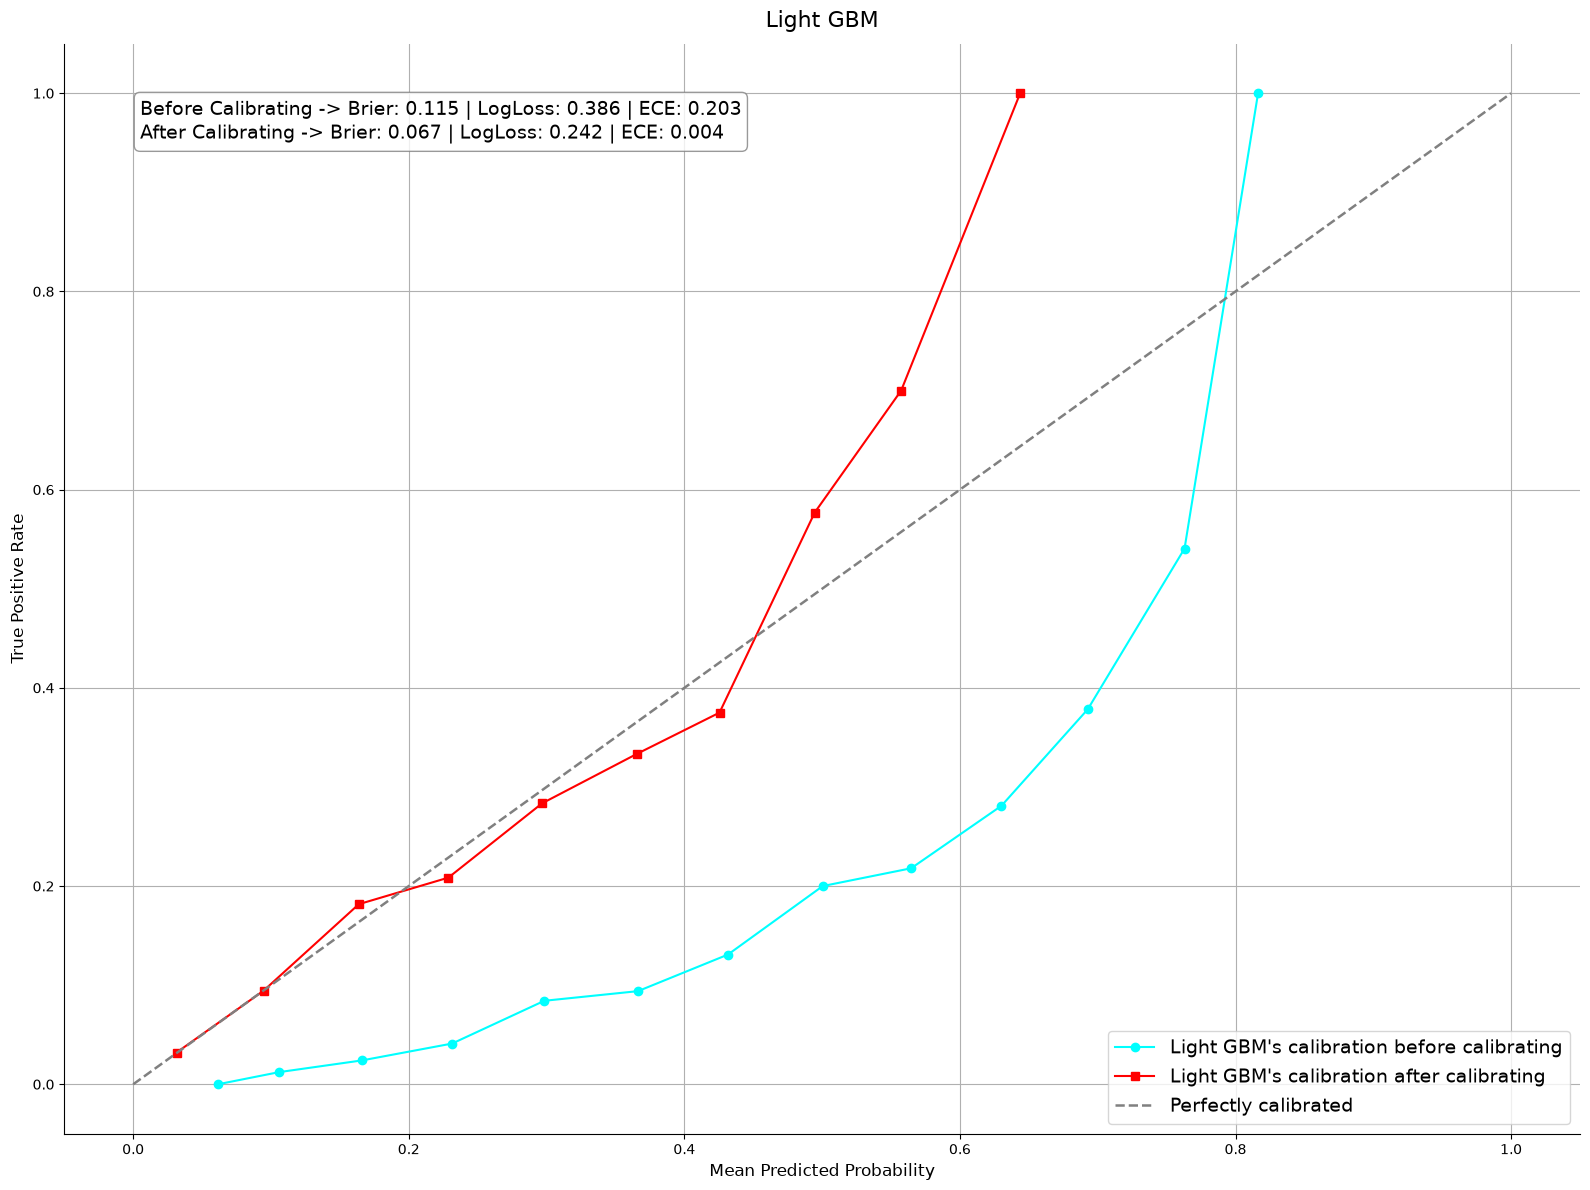

In [23]:
improve_calibration = ImproveModelCalibration(X_val=X_val, y_val=y_val, X_test=X_test, y_test=y_test, method='sigmoid')

estimators_dict = {
    'Light GBM': lgb_tuned_pipeline_with_weight,
}
plots_each_row = 1

calibrated_estimators_dict = improve_calibration.calibration_plot_before_after_calibrating(estimators_dict, plots_each_row)

In [24]:
import joblib

calibrated_lgb_with_weight = calibrated_estimators_dict['Calibrated Light GBM']

joblib.dump(calibrated_lgb_with_weight, '/Users/thuyduc/Projects/AI/AI Sandbox/Services/CreditRiskAgent/models/saved_models/calibrated_lgb_with_weight_tuned_pipeline.joblib')

['/Users/thuyduc/Projects/AI/AI Sandbox/Services/CreditRiskAgent/models/saved_models/calibrated_lgb_with_weight_tuned_pipeline.joblib']

In [21]:
# kiểm tra perfomance của các model trên đối với tập val dataset
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score
class TestPerformance:
    def __init__(self, X: pd.DataFrame, y:pd.Series):
        self.x = X
        self.y = y

    def model_performance(self, estimators_dict:dict, use_prob:bool, threshold:float=0.5, metrics_fn:dict[str, tuple]={'F1 Score':(f1_score, {})}):
        """
        use_prob: True if metrics_fn requires estimated probabilities, False otherwise
        threshold: only used when use_prob = False
        """
        
        # Initialize result container
        data = {
            'Model': list(estimators_dict.keys())
        }
    
        # Initialize metric columns
        for metric_name in metrics_fn:
            data[metric_name] = []
    
        # Compute predictions & metrics
        for name, estimator in estimators_dict.items():
            y_prob_positive = estimator.predict_proba(self.x)[:, 1]
            
            if use_prob == True:
                y = y_prob_positive
            else:
                y_pred = (y_prob_positive >= threshold).astype(int)
                y = y_pred
    
            for metric_name, (metric_fn, kwargs) in metrics_fn.items():
                score = metric_fn(self.y, y, **kwargs)
                data[metric_name].append(score)

        return pd.DataFrame(data)

In [29]:
calibrated_lgb_with_weight = calibrated_estimators_dict['Calibrated Light GBM']

tester = TestPerformance(X_val, y_val)

estimators_dict={
    'Calibrated Light GBM': calibrated_lgb_with_weight,
    'Light GBM': lgb_tuned_pipeline_with_weight,
}

metrics_fn={
    'ROC-AUC': (roc_auc_score, {'average':'weighted'}),
    'PR-AUC': (average_precision_score, {'average':'weighted'}),
}

data = tester.model_performance(estimators_dict=estimators_dict, metrics_fn=metrics_fn, use_prob=True)
data

,Model,ROC-AUC,PR-AUC
0,Calibrated Light GBM,0.770602,0.250395
1,Light GBM,0.770602,0.250395


# Improve Model Calibration for LightGBM without ClassWeighting

## Load Pipeline

In [23]:
import joblib
merge_pipeline_without_weight = joblib.load('/kaggle/input/models/thuyduc/lightgbm-without-class-weighting/scikitlearn/default/1/merge_pipeline.joblib')
lgb_tuned_pipeline_without_weight = joblib.load('/kaggle/input/models/thuyduc/lightgbm-without-class-weighting/scikitlearn/default/1/lgb_tuned_pipeline.joblib')

In [24]:
final_dataset_val = merge_pipeline_without_weight.transform(bureau_balance_val, POS_CASH_balance_val, application_train_val, credit_card_balance_val, \
                                              previous_application_val, bureau_val, installments_payments_val)

final_dataset_test = merge_pipeline_without_weight.transform(bureau_balance_test, POS_CASH_balance_test, application_train_test, credit_card_balance_test, \
                                              previous_application_test, bureau_test, installments_payments_test)

# final_dataset_train = merge_pipeline_.transform(bureau_balance_train, POS_CASH_balance_train, application_train_train, credit_card_balance_train, \
#                                               previous_application_train, bureau_train, installments_payments_train)

/tmp/ipykernel_58/1809094098.py:39: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_agg.reset_index(inplace=True)
/tmp/ipykernel_58/1809094098.py:39: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_agg.reset_index(inplace=True)


In [25]:
X_val = final_dataset_val.drop(columns=['AT_TARGET', 'SK_ID_CURR'])
y_val = final_dataset_val['AT_TARGET']

X_test = final_dataset_test.drop(columns=['AT_TARGET', 'SK_ID_CURR'])
y_test = final_dataset_test['AT_TARGET']

# X_train = final_dataset_train.drop(columns=['AT_TARGET', 'SK_ID_CURR'])
# y_train = final_dataset_train['AT_TARGET']

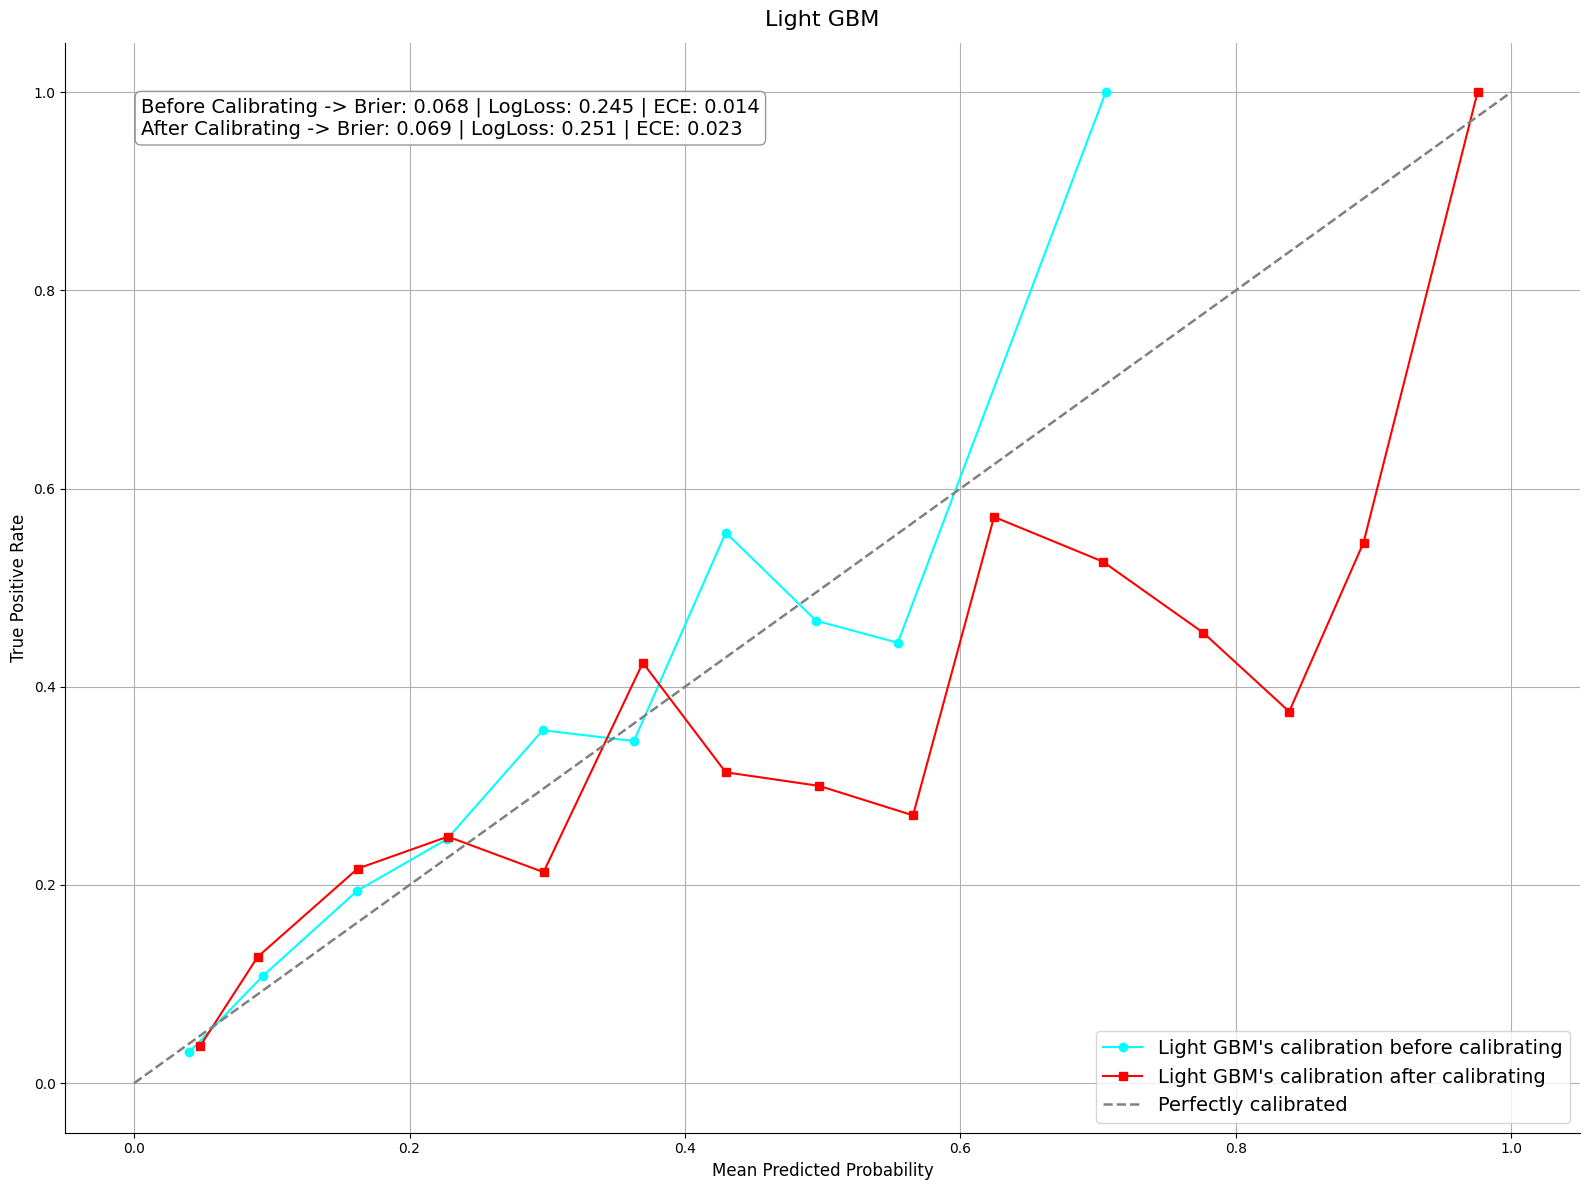

In [28]:
improve_calibration = ImproveModelCalibration(X_val=X_val, y_val=y_val, X_test=X_test, y_test=y_test, method='sigmoid')

estimators_dict = {
    'Light GBM': lgb_tuned_pipeline_without_weight,
}
plots_each_row = 1

calibrated_estimators_dict = improve_calibration.calibration_plot_before_after_calibrating(estimators_dict, plots_each_row)

In [40]:
calibrated_lgb_without_weight = calibrated_estimators_dict['Calibrated Light GBM']

tester = TestPerformance(X_val, y_val)

estimators_dict={
    'Calibrated Light GBM': calibrated_lgb_without_weight,
    'Light GBM': lgb_tuned_pipeline_without_weight,
}

metrics_fn={
    'ROC-AUC': (roc_auc_score, {'average':'weighted'}),
    'PR-AUC': (average_precision_score, {'average':'weighted'}),
}

data = tester.model_performance(estimators_dict=estimators_dict, metrics_fn=metrics_fn, use_prob=True)
data

,Model,ROC-AUC,PR-AUC
0,Calibrated Light GBM,0.768273,0.249795
1,Light GBM,0.768273,0.249795
